# Векторы

In [2]:
import numpy as np

a = np.array([2,1])
b = np.array([1,3])

print(f"a + b: {a+b}") # [3, 4]
print(f"a - b: {a-b}") # [1, -2]
print(f"2*a - 3*b: {2*a-3*b}") # [1, -7]
print(f"a*b: {a@b}") # 5 или np.dot(a, b)

a + b: [3 4]
a - b: [ 1 -2]
2*a - 3*b: [ 1 -7]
a*b: 5


In [4]:
import numpy as np

a = np.array([2, 1])
b = np.array([1, 3])

# |v| = sqrt(v0² + v1²)
norm_a = np.linalg.norm(a)
norm_b = np.linalg.norm(b)

print(f"|a| = {norm_a:.4f}")
print(f"|b| = {norm_b:.4f}")

'''
- dot – скалярное произведение векторов
- определение угла через скалярное произведение
'''
cos_theta = np.dot(a,b) / (norm_a * norm_b)
print(f"cos(θ) = {cos_theta:.4f}")

'''
- np.clip(cos_theta, -1.0, 1.0) нужен из-за погрешности float64
- Иногда cos_theta получается 1.0000000000000002, и arccos от такого числа даст nan. clip ограничивает диапазон [-1, 1]
'''
theta_rad = np.arccos(np.clip(cos_theta, -1.0, 1.0)) # 
print(f"θ = {theta_rad:.4f} рад")

theta_deg = np.degrees(theta_rad) # convert rad to degrees
print(f"θ = {theta_deg:.2f}°")

|a| = 2.2361
|b| = 3.1623
cos(θ) = 0.7071
θ = 0.7854 рад
θ = 45.00°


In [7]:
# проверь, являются ли векторы линейно независимыми
import numpy as np

a = np.array([2, 1])
b = np.array([1, 3])

M = np.column_stack([a, b]) # column_stack - stack 1-D arrays as columns into a 2-D array.
det = np.linalg.det(M) # determinator

print(f"M:\n {M}")
print(f"det = {det:.2f}")
print("являются ли векторы линейно независимыми:", not np.isclose(det, 0))

M:
 [[2 1]
 [1 3]]
det = 5.00
являются ли векторы линейно независимыми: True


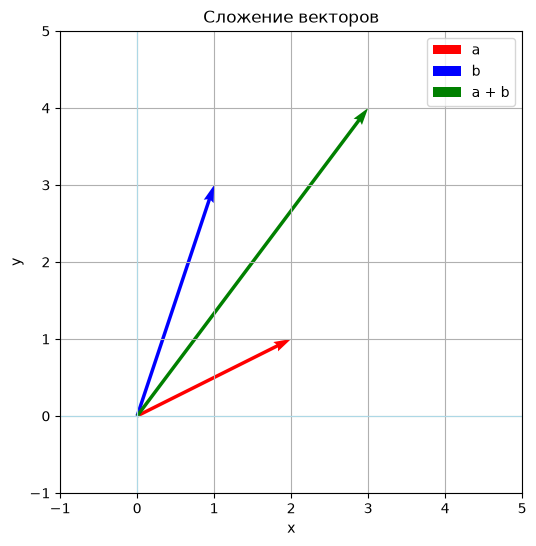

In [31]:
import numpy as np
import matplotlib.pyplot as plt

a = np.array([2, 1])
b = np.array([1, 3])
a_plus_b = a + b

plt.figure(figsize=(6, 6))

'''
- quiver(X, Y, U, V)
- X, Y     — начало стрелки
- U, V     — компоненты вектора по осям x и y
- *a       — распаковать a=[U, V]
- angles   — как интерпретировать направление
- scale_units — единицы измерения длины
- scale    — масштаб стрелки
- color    — цвет
- label    — название в легенде
'''
plt.quiver(
    0, 0, 
    a[0], a[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="red",
    label="a",
)

plt.quiver(
    0, 0, *b,
    angles="xy",
    scale_units="xy",
    scale=1,
    color="blue", 
    label="b",
)

plt.quiver(
    0, 0, *a_plus_b,
    angles="xy",
    scale_units="xy",
    scale=1,  
    color="green", 
    label="a + b",
)

# оси по x и y от нуля до предела
plt.axhline(0, color="lightblue", linewidth=0.8)
plt.axvline(0, color="lightblue", linewidth=0.8)

plt.xlim(-1, 5)
plt.ylim(-1, 5)
'''
Эта строка делает одинаковый масштаб по осям X и Y.
- plt.gca(): gca означает get current axes — получить текущую область графика.
- .set_aspect("equal"): Устанавливает одинаковое соотношение масштаба:

Без этой строки график может визуально растянуться по одной из осей.
'''
plt.gca().set_aspect('equal')

plt.xlabel("x")
plt.ylabel("y")
plt.title("Сложение векторов")
plt.grid(True)
plt.legend()
plt.show()

In [32]:
import numpy as np

a = np.array([1, 2])
b = np.array([3, 4])

# Скалярное произведение
dot_product = np.dot(a, b)

# Длины векторов
a_norm = np.linalg.norm(a)
b_norm = np.linalg.norm(b)

# Косинусная мера
cosine_similarity = dot_product / (a_norm * b_norm)

print("Скалярное произведение:", dot_product)
print("Длина a:", a_norm)
print("Длина b:", b_norm)
print("Косинусная мера:", cosine_similarity)

# Определяем направление
if dot_product > 0:
    print("Векторы направлены примерно в одну сторону")
elif np.isclose(dot_product, 0):
    print("Векторы перпендикулярны")
else:
    print("Векторы направлены примерно в противоположные стороны")

Скалярное произведение: 11
Длина a: 2.23606797749979
Длина b: 5.0
Косинусная мера: 0.9838699100999074
Векторы направлены примерно в одну сторону


# Матрица и линейные преобразования

In [36]:
import numpy as np

matrix_a = np.array([
    [2, 1],
    [1, 3],
])

matrix_b = np.array([
    [1, 2], 
    [0, 1],
])

matrix_a_plub_b = matrix_a + matrix_b
print(f"резльутат сложения матриц A и B: {matrix_a_plub_b}")

matrix_a_multipy_b = matrix_a * matrix_b
print(f"резльутат умножения матриц A и B: {matrix_a_multipy_b}")

matrix_b_multipy_a = matrix_b * matrix_a
print(f"резльутат умножения матриц B и A: {matrix_b_multipy_a}")

'''
Умножение матриц некоммутативно: порядок матриц имеет значение. => AB и BA – отличаться
'''

резльутат сложения матриц A и B: [[3 3]
 [1 4]]
резльутат умножения матриц A и B: [[2 2]
 [0 3]]
резльутат умножения матриц B и A: [[2 2]
 [0 3]]


'\nУмножение матриц некоммутативно: порядок матриц имеет значение. => AB и BA – отличаться\n'

A · e₁: [1 0] → [2 1]
A · e₂: [0 1] → [1 3]
B · e₁: [1 0] → [1 0]
B · e₂: [0 1] → [2 1]


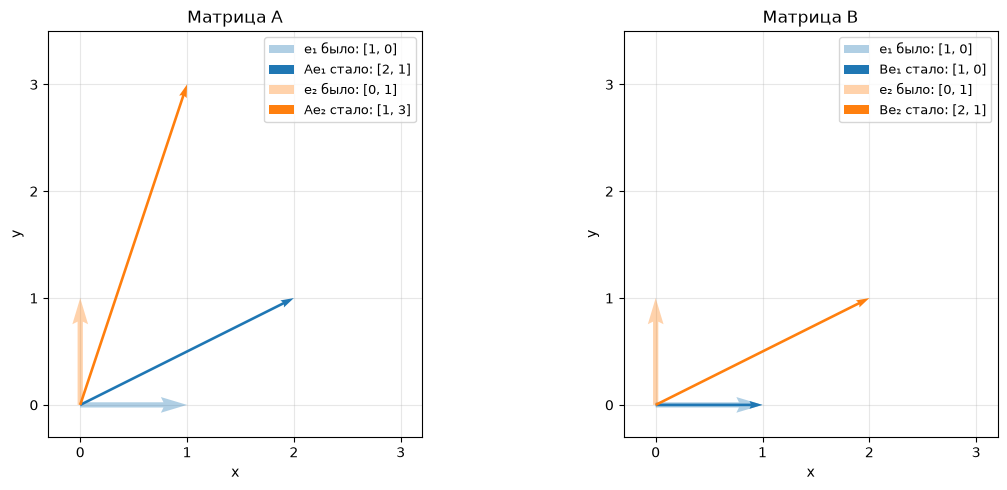

In [61]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[2, 1],
              [1, 3]])
B = np.array([[1, 2],
              [0, 1]])

e1 = np.array([1, 0])
e2 = np.array([0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax_a = axes[0]
ax_b = axes[1]

# is_result — это параметр функции, который отвечает на вопрос: «Это стрелка результата?» (было/стало)
def draw_vector(ax, vector, color, label, is_result):
    """Рисует вектор стрелкой из точки (0, 0)."""
    x = vector[0]
    y = vector[1]

    ax.quiver(
        0, 0, x, y,                # Начало (0, 0), направление (x, y)
        angles="xy",
        scale_units="xy",
        scale=1,                   # Длина стрелки соответствует координатам
        color=color,
        alpha=1 if is_result else 0.35,
        width=0.007 if is_result else 0.014,
        zorder=3 if is_result else 2,
        label=label,
    )


# Матрица A, первый вектор
a_e1 = A @ e1
print(f"A · e₁: {e1} → {a_e1}")

draw_vector(ax_a, e1, "tab:blue", "e₁ было: [1, 0]", False)
draw_vector(ax_a, a_e1, "tab:blue", "Ae₁ стало: [2, 1]", True)

# Матрица A, второй вектор
a_e2 = A @ e2
print(f"A · e₂: {e2} → {a_e2}")

draw_vector(ax_a, e2, "tab:orange", "e₂ было: [0, 1]", False)
draw_vector(ax_a, a_e2, "tab:orange", "Ae₂ стало: [1, 3]", True)

# Матрица B, первый вектор
b_e1 = B @ e1
print(f"B · e₁: {e1} → {b_e1}")

draw_vector(ax_b, e1, "tab:blue", "e₁ было: [1, 0]", False)
draw_vector(ax_b, b_e1, "tab:blue", "Be₁ стало: [1, 0]", True)

# Матрица B, второй вектор
b_e2 = B @ e2
print(f"B · e₂: {e2} → {b_e2}")

draw_vector(ax_b, e2, "tab:orange", "e₂ было: [0, 1]", False)
draw_vector(ax_b, b_e2, "tab:orange", "Be₂ стало: [2, 1]", True)

# Названия графиков
ax_a.set_title("Матрица A")
ax_b.set_title("Матрица B")

# Одинаковые настройки для двух графиков
for ax in (ax_a, ax_b):
    ax.set_xlim(-0.3, 3.2)
    ax.set_ylim(-0.3, 3.5)
    ax.set_aspect("equal")
    ax.set_xticks([0, 1, 2, 3])
    ax.set_yticks([0, 1, 2, 3])
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_axisbelow(True)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

'''
Как каждая матрица меняет пространство?

A меняет направления координатных осей и увеличивает площадь фигур в 5 раз.
B наклоняет сетку: точка (x, y) переходит в (x + 2y, y). При этом B сохраняет площадь фигур.
'''

# Определитель, обратная матрица и система уравнений

In [71]:
import numpy as np

A = np.array([[2, 1],
              [1, 3]])

'''
квадрат площадью 1 после преобразования A станет параллелограммом площадью 5. Положительный знак определителя означает, что ориентация пространства сохранилась.
'''
det_A = np.linalg.det(A)
print(f"Определитель A: {det_A:.2f}")

if not np.isclose(det_A, 0):
    A_inverse = np.linalg.inv(A)
    print(f"Обратная матрица: {A_inverse}")
    is_A_inverse_right = A @ A_inverse
    print(f"Проверка A @ A_inverse: {is_A_inverse_right}")
else:
    print("Определитель равен нулю: обратной матрицы нет")

Определитель A: 5.00
Обратная матрица: [[ 0.6 -0.2]
 [-0.2  0.4]]
Проверка A @ A_inverse: [[ 1.00000000e+00  0.00000000e+00]
 [-5.55111512e-17  1.00000000e+00]]


In [73]:
A = np.array([[2, 1],
              [1, 3]])
b = np.array([5, 7])

x = np.linalg.solve(A, b)
print("Решение:", x)

result = A @ x
print("Ax =", result)
print("Совпадает с b:", np.allclose(result, b))

Решение: [1.6 1.8]
Ax = [5. 7.]
Совпадает с b: True


Определитель C: 0.0


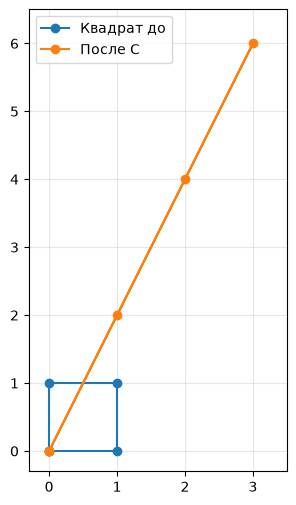

In [74]:
C = np.array([[1, 2], [2, 4]])

square = np.array([[0, 0], [1, 0], [1, 1], [0, 1], [0, 0]])
transformed = (C @ square.T).T

print("Определитель C:", np.linalg.det(C))

plt.figure(figsize=(6, 6))
plt.plot(square[:, 0], square[:, 1], "o-", label="Квадрат до")
plt.plot(transformed[:, 0], transformed[:, 1], "o-", label="После C")
plt.xlim(-0.3, 3.5)
plt.ylim(-0.3, 6.5)
plt.gca().set_aspect("equal")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# На графике исходный квадрат превратится в отрезок прямой. Поэтому у \(C\) нет обратной матрицы: восстановить исходную точку по результату однозначно невозможно.

# Базис и линейная зависимость

In [78]:
import numpy as np

v1 = np.array([1, 0, 1])
v2 = np.array([0, 1, 1])
v3 = np.array([1, 1, 2])
u = np.array([3, 2])

print(f"v1 + v2 = {v1 + v2}")
print(f"Совпадает ли с v3? – {np.array_equal(v1 + v2, v3)}")

union_V = np.column_stack((v1, v2, v3))
print(f"Ранг: {np.linalg.matrix_rank(union_V)}")

v1 + v2 = [1 1 2]
Совпадает ли с v3? – True
Ранг: 2


In [85]:
e1 = np.array([1, 1])
e2 = np.array([1, -1])
u = np.array([3, 2])

basis = np.column_stack((e1, e2))
coordinates = np.linalg.solve(basis, u)
print("Координаты u в новом базисе:", coordinates)

restored_u = basis @ coordinates

print("Восстановленный вектор:", restored_u)
print("Совпадает с u:", np.allclose(restored_u, u))

Координаты u в новом базисе: [2.5 0.5]
Восстановленный вектор: [3. 2.]
Совпадает с u: True


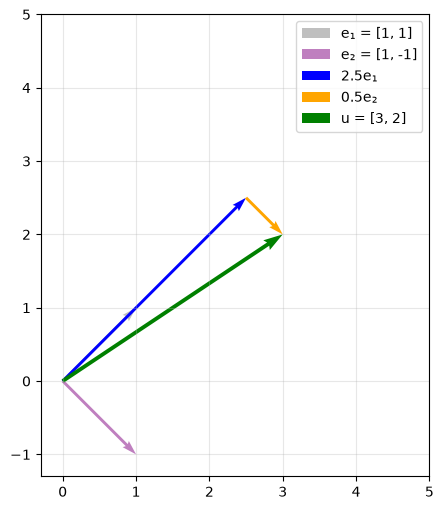

In [86]:
import matplotlib.pyplot as plt

first_step = coordinates[0] * e1
second_step = coordinates[1] * e2

fig, ax = plt.subplots(figsize=(7, 6))

# Новые направления базиса
ax.quiver(0, 0, *e1, angles="xy", scale_units="xy", scale=1,
          color="gray", alpha=0.5, label="e₁ = [1, 1]")
ax.quiver(0, 0, *e2, angles="xy", scale_units="xy", scale=1,
          color="purple", alpha=0.5, label="e₂ = [1, -1]")

# Путь: сначала 2.5e₁, затем 0.5e₂
ax.quiver(0, 0, *first_step, angles="xy", scale_units="xy", scale=1,
          color="blue", label="2.5e₁")
ax.quiver(*first_step, *second_step, angles="xy", scale_units="xy",
          scale=1, color="orange", label="0.5e₂")

# Исходный вектор для сравнения
ax.quiver(0, 0, *u, angles="xy", scale_units="xy", scale=1,
          color="green", width=0.01, label="u = [3, 2]")

ax.set_xlim(-0.3, 5)
ax.set_ylim(-1.3, 5)
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# Собственные значения и собственные векторы

In [90]:
import numpy as np

C = np.array([[2, 1],
              [1, 2]])

v3 = np.array([1, 1])
v1 = np.array([1, -1])

print("Для λ=3:", (C - 3 * np.eye(2)) @ v3)
print("Для λ=1:", (C - 1 * np.eye(2)) @ v1)

Для λ=3: [0. 0.]
Для λ=1: [0. 0.]


In [91]:
eigenvalues, eigenvectors = np.linalg.eig(C)

for i, value in enumerate(eigenvalues):
    print(f"λ = {value:.1f}, вектор = {eigenvectors[:, i]}")

λ = 3.0+0.0j, вектор = [0.70710678+0.j 0.70710678+0.j]
λ = 1.0+0.0j, вектор = [-0.70710678+0.j  0.70710678+0.j]


In [92]:
for value, vector in [(3, v3), (1, v1)]:
    left = C @ vector
    right = value * vector
    print(f"λ={value}: Cv={left}, λv={right}, совпадают={np.array_equal(left, right)}")

λ=3: Cv=[3 3], λv=[3 3], совпадают=True
λ=1: Cv=[ 1 -1], λv=[ 1 -1], совпадают=True


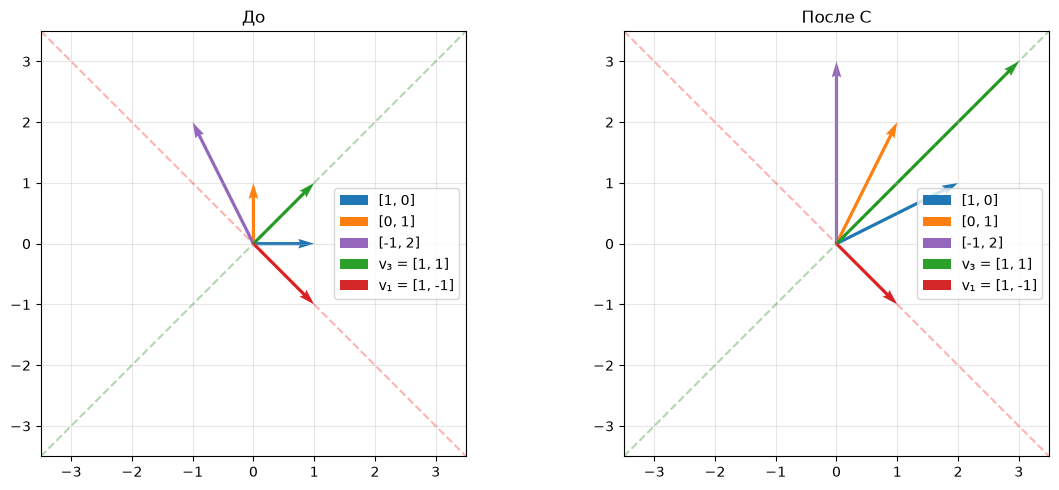

In [93]:
import matplotlib.pyplot as plt

vectors = [
    ("[1, 0]", np.array([1, 0]), "tab:blue"),
    ("[0, 1]", np.array([0, 1]), "tab:orange"),
    ("[-1, 2]", np.array([-1, 2]), "tab:purple"),
    ("v₃ = [1, 1]", v3, "tab:green"),
    ("v₁ = [1, -1]", v1, "tab:red"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, matrix, title in [
    (axes[0], np.eye(2), "До"),
    (axes[1], C, "После C"),
]:
    ax.axline((0, 0), slope=1, color="green", alpha=0.3, linestyle="--")
    ax.axline((0, 0), slope=-1, color="red", alpha=0.3, linestyle="--")

    for label, vector, color in vectors:
        shown = matrix @ vector
        ax.quiver(0, 0, *shown, angles="xy", scale_units="xy",
                  scale=1, color=color, label=label)

    ax.set_title(title)
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()